In [9]:
# change in loaddata.py to "augmented_maps2d/gaussian_alpha_005"
import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the parent directory to the path so we can import Danial/Alen's code
sys.path.append(os.path.abspath(".."))

from train_single import get_model_class
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [ ]:
from loaddata import load_level_data
from torch.utils.data import TensorDataset, DataLoader
import math

def evaluate_model_on_folder(model_name, level, data_root):
    """Loads a pre-trained model and evaluates it using proper preprocessing."""
    
    _, _, X_val, Y_val = load_level_data(level=level, val_fold=5, root=data_root)
    
    val_dataset = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32), 
        torch.tensor(Y_val, dtype=torch.float32)
    )
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    
    model_class = get_model_class(model_name)
    model = model_class().to(device)
    
    weights_path = f"../checkpoints/{model_name}_level{level}.pth"
    if os.path.exists(weights_path):
        model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
    else:
        print(f"Warning: No weights found at {weights_path}. Evaluating untrained model!")
        
    model.eval()
    
    total_mae_omega_m = 0.0
    total_mae_sigma_8 = 0.0
    total_sqerr_omega_m = 0.0
    total_sqerr_sigma_8 = 0.0
    num_samples = 0
    
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            predictions = model(bx)
            
            batch_size = bx.size(0)
            num_samples += batch_size
            
            # MAE (Absolute Errors)
            total_mae_omega_m += torch.sum(torch.abs(predictions[:, 0] - by[:, 0])).item()
            total_mae_sigma_8 += torch.sum(torch.abs(predictions[:, 1] - by[:, 1])).item()
            
            # MSE (Squared Errors for RMSE later)
            total_sqerr_omega_m += torch.sum((predictions[:, 0] - by[:, 0])**2).item()
            total_sqerr_sigma_8 += torch.sum((predictions[:, 1] - by[:, 1])**2).item()

    # Calculate final MAE and RMSE
    return {
        "Omega_m MAE": total_mae_omega_m / num_samples,
        "Sigma_8 MAE": total_mae_sigma_8 / num_samples,
        "Omega_m RMSE": math.sqrt(total_sqerr_omega_m / num_samples),
        "Sigma_8 RMSE": math.sqrt(total_sqerr_sigma_8 / num_samples)
    }

In [11]:
# Configuration
MODEL_TO_TEST = "model_10_5"  # Use one of the names from the JSON files you showed me
LEVEL = 3                     

# The directories we want to compare
directories_to_test = {
    "Original (Clean)": "maps2d",
    "Gaussian Noise (1%)": "augmented_maps2d/gaussian_alpha_001",
    "Gaussian Noise (5%)": "augmented_maps2d/gaussian_alpha_005"
}

results = {}

for label, folder in directories_to_test.items():
    print(f"\n--- Testing on: {label} ---")
    try:
        metrics = evaluate_model_on_folder(MODEL_TO_TEST, LEVEL, folder)
        results[label] = metrics
    except Exception as e:
        print(f"Error loading {folder}: {e}")

# Convert to a beautiful Pandas DataFrame
df_results = pd.DataFrame(results).T
display(df_results)


--- Testing on: Original (Clean) ---
Loading data for Level 3 from 'maps2d' (Validation on Fold 5)...

--- Testing on: Gaussian Noise (1%) ---
Loading data for Level 3 from 'augmented_maps2d/gaussian_alpha_001' (Validation on Fold 5)...

--- Testing on: Gaussian Noise (5%) ---
Loading data for Level 3 from 'augmented_maps2d/gaussian_alpha_005' (Validation on Fold 5)...


,Total MSE,Omega_m MAE,Sigma_8 MAE
Original (Clean),0.000762,0.016145,0.025527
Gaussian Noise (1%),20.571227,2.393655,4.118955
Gaussian Noise (5%),11.107728,0.611783,4.400323


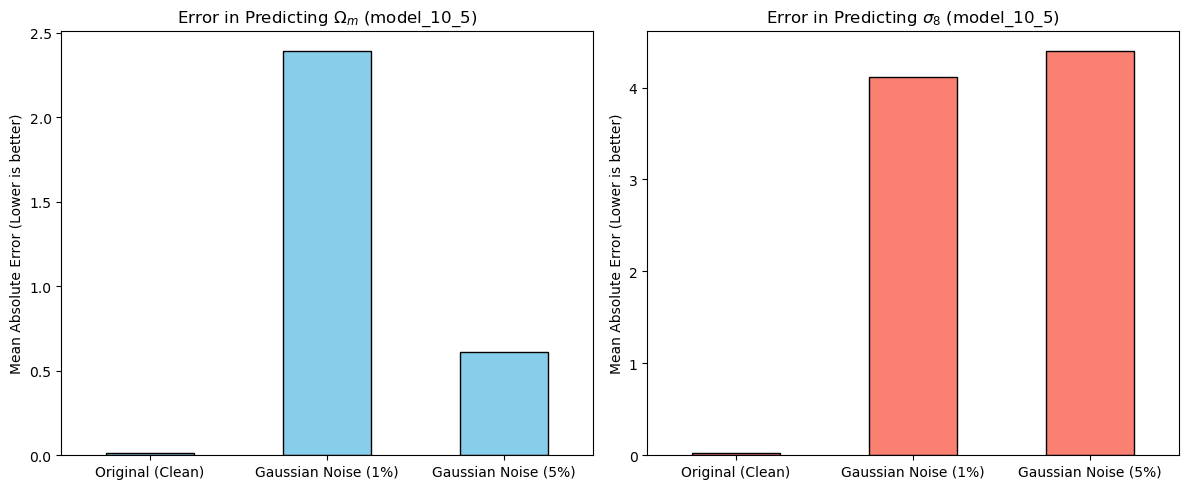

In [ ]:
# Create a 2x2 grid of plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- ROW 1: MAE ---
df_results['Omega_m MAE'].plot(kind='bar', ax=axes[0, 0], color='skyblue', edgecolor='black')
axes[0, 0].set_title(f"MAE for $\Omega_m$ ({MODEL_TO_TEST})")
axes[0, 0].set_ylabel("Mean Absolute Error")
axes[0, 0].tick_params(axis='x', rotation=0)

df_results['Sigma_8 MAE'].plot(kind='bar', ax=axes[0, 1], color='salmon', edgecolor='black')
axes[0, 1].set_title(f"MAE for $\sigma_8$ ({MODEL_TO_TEST})")
axes[0, 1].tick_params(axis='x', rotation=0)

# --- ROW 2: RMSE ---
df_results['Omega_m RMSE'].plot(kind='bar', ax=axes[1, 0], color='deepskyblue', edgecolor='black')
axes[1, 0].set_title(f"RMSE for $\Omega_m$ ({MODEL_TO_TEST})")
axes[1, 0].set_ylabel("Root Mean Square Error")
axes[1, 0].tick_params(axis='x', rotation=0)

df_results['Sigma_8 RMSE'].plot(kind='bar', ax=axes[1, 1], color='tomato', edgecolor='black')
axes[1, 1].set_title(f"RMSE for $\sigma_8$ ({MODEL_TO_TEST})")
axes[1, 1].tick_params(axis='x', rotation=0)

# Adjust layout so labels don't overlap
plt.tight_layout()

# Save the chart!
plt.savefig(f"{MODEL_TO_TEST}_noise_comparison.png", dpi=300, bbox_inches='tight')
plt.show()